# 01 · 大促 GMV 归因与备货

大促复盘最常见的两种错误：**「GMV 涨了 60%，因为我们投了更多流量」**，以及
**「客单价涨了 43 块，因为凑单机制做得好」**。前者忽略转化和客单的贡献，后者把品类结构升级算成了运营提效。

这个 Notebook 做三件事：

1. 用**恒等式**把 GMV 增幅拆成客流 / 转化 / 客单三层，做到零残差；
2. 再把转化率与客单价拆成「各品类自身变化」与「品类结构变化」，把结构贡献单独拎出来；
3. 把归因结果接到备货上：不同服务水平对应多少库存、多少缺货率。

> 数据是同构的（`src/gen.py`），四个效应按已知参数埋入，所以能验证分解是否拆对。

## 1. 数据

两期：2024 与 2025 的双 11 周期（11-01 ~ 11-11），一行 = 品类 × 日。
字段：`uv`（去重 UV）、`cvr`（下单转化率）、`aov`（客单价）、`orders`、`gmv`。

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.gen import build, save
from src.decompose import (category_totals, totals, decompose_total, shift_share,
                           category_contribution, stockout_tradeoff)

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
print("仓库根目录：", ROOT)

仓库根目录： C:\Users\50521\Desktop\chenism\portfolio\ecom-promo


In [2]:
out = ROOT / "outputs"
if not (out / "promo_category_daily.csv").exists():
    df, truth = build()
    save(df, truth, out)
else:
    df = pd.read_csv(out / "promo_category_daily.csv", parse_dates=["date"])
    truth = json.loads((out / "ground_truth.json").read_text(encoding="utf-8"))

print(f"{len(df)} 行｜品类 {df.category.nunique()} 个｜两期各 {df.day_index.nunique()} 天")
totals(df).round(3)

176 行｜品类 8 个｜两期各 11 天


,year,uv,orders,gmv,days,cvr,aov
0,2024,476551.886,1446732.0,2.992601e+08,11,0.276,206.852
1,2025,559289.955,1923048.0,4.801103e+08,11,0.313,249.661


## 2. 三层分解：GMV = UV × CVR × AOV

链式顺序分解，三项之和精确等于增量（不留残差）：

```
ΔGMV = ΔUV·CVR₀·AOV₀  +  UV₁·ΔCVR·AOV₀  +  UV₁·CVR₁·ΔAOV
        客流效应            转化效应            客单效应
```

这不是模型，是代数恒等——所以**闭合误差必须为 0**。真实项目里报的「误差 3% 以内」，
误差全部来自口径（退款剔除、跨端去重、定金与尾款归属），而不是公式本身。

In [3]:
d = decompose_total(df)
summary = pd.DataFrame([
    {"项": "2024 GMV", "金额（万元）": d["gmv_base"] / 1e4, "占增量": None},
    {"项": "2025 GMV", "金额（万元）": d["gmv_cur"] / 1e4, "占增量": None},
    {"项": "同比增量", "金额（万元）": d["gmv_delta"] / 1e4, "占增量": f"{d['growth']:+.1%}"},
    {"项": "　客流效应", "金额（万元）": d["uv_effect"] / 1e4, "占增量": f"{d['uv_contrib']:.1%}"},
    {"项": "　转化效应", "金额（万元）": d["cvr_effect"] / 1e4, "占增量": f"{d['cvr_contrib']:.1%}"},
    {"项": "　客单效应", "金额（万元）": d["aov_effect"] / 1e4, "占增量": f"{d['aov_contrib']:.1%}"},
])
print(f"闭合误差：{d['closure_error']:.2f} 元（{d['closure_error_pct']:.4%}）")
summary.round(1)

闭合误差：-0.00 元（-0.0000%）


,项,金额（万元）,占增量
0,2024 GMV,29926.0,NaN
1,2025 GMV,48011.0,NaN
2,同比增量,18085.0,+60.4%
3,客流效应,5195.7,28.7%
4,转化效应,4657.0,25.8%
5,客单效应,8232.3,45.5%


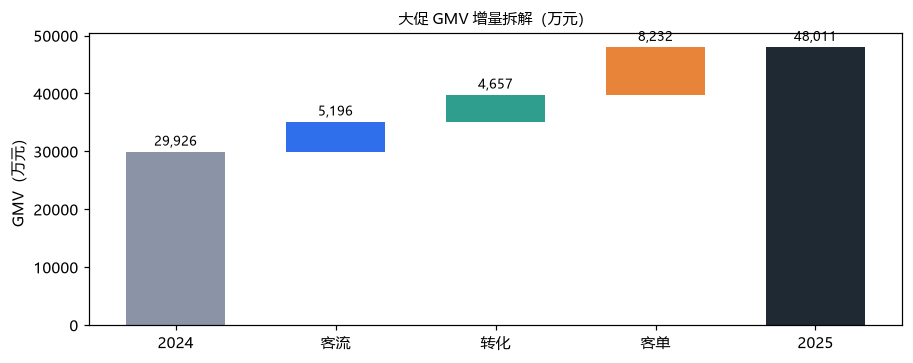

In [4]:
fig, ax = plt.subplots(figsize=(8.4, 3.4))
labels = ["2024", "客流", "转化", "客单", "2025"]
vals = [d["gmv_base"] / 1e4, d["uv_effect"] / 1e4, d["cvr_effect"] / 1e4,
        d["aov_effect"] / 1e4, d["gmv_cur"] / 1e4]
bottoms = [0, vals[0], vals[0] + vals[1], vals[0] + vals[1] + vals[2], 0]
colors = ["#8a94a6", "#2f6feb", "#2f9e8f", "#e8833a", "#1f2933"]
for i, (v, b, c) in enumerate(zip(vals, bottoms, colors)):
    ax.bar(i, v, bottom=b, color=c, width=0.62)
    ax.annotate(f"{v:,.0f}", xy=(i, b + v), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8.5)
ax.set_xticks(range(5), labels)
ax.set_ylabel("GMV（万元）")
ax.set_title("大促 GMV 增量拆解（万元）", fontsize=10)
plt.tight_layout(); plt.show()

**客流贡献不到三成，客单贡献接近一半。** 如果复盘只讲「流量涨了」，会漏掉最大的那块。

但「客单贡献」还不能直接归功于运营——要看它是「同品类卖得更贵」还是「贵的品类卖得更多」。

## 3. 结构与自身：把「品类升级」从「运营提效」里剥出来

CVR 与 AOV 的总体变化都可以拆成两项：

- **mix（结构）**：品类之间的份额变了，即使各品类自身没变，总体指标也会变；
- **within（自身）**：各品类自己的指标变了，这才是运营动作的直接结果。

权重口径要分开：CVR 按 UV 份额加权，AOV 按订单份额加权——用错权重会得到一堆误导结论。

In [5]:
mix = shift_share(df)
mix["mix 占比"] = mix["结构效应 mix"] / mix["总体变化"]
mix.round(4)

,指标,总体变化,结构效应 mix,自身效应 within,mix 占比
0,转化率 CVR,0.0046,-0.0004,0.0050,-0.0828
1,客单价 AOV,42.8086,15.3423,27.4663,0.3584


两件事值得说：

1. **转化率的提升基本来自自身**（mix 甚至是负的），说明大促的转化优化是真的；
2. **客单价的增长里有三成以上来自结构**——数码、美妆的流量份额涨了，把平均客单价「抬」上去了。

如果不做这层拆分，就会得出「凑单机制让客单价涨了 43 块」的错误结论，
下次照这个思路继续投凑单，效果一定不及预期。

In [6]:
cc = category_contribution(df)
cc[["gmv_base", "gmv_cur", "contrib", "uv_share_base", "uv_share_cur", "uv_share_chg_pp"]].round(4)

,gmv_base,gmv_cur,contrib,uv_share_base,uv_share_cur,uv_share_chg_pp
category,,,,,,
数码,50475802.90,1.112864e+08,0.3362,0.0667,0.0937,2.6996
美妆,55217215.02,1.027198e+08,0.2627,0.1439,0.1627,1.8812
女装,54059696.32,7.431933e+07,0.1120,0.2151,0.1998,-1.5388
食品,39524347.76,5.725920e+07,0.0981,0.1817,0.1839,0.2173
家居,20980082.30,3.100122e+07,0.0554,0.0793,0.0770,-0.2263
男装,34079339.75,4.240805e+07,0.0461,0.1662,0.1439,-2.2281
母婴,32362427.29,4.059529e+07,0.0455,0.0848,0.0736,-1.1173
运动,12561211.98,2.052102e+07,0.0440,0.0623,0.0654,0.3124


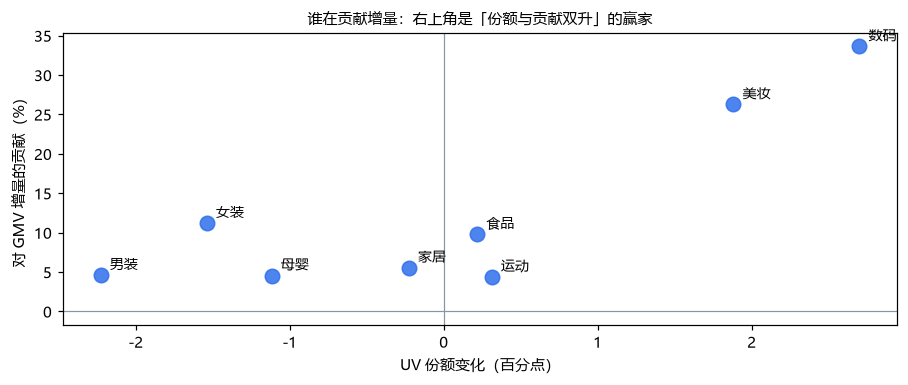

In [7]:
top = cc.head(8)
fig, ax = plt.subplots(figsize=(8.4, 3.6))
ax.scatter(top["uv_share_chg_pp"], top["contrib"] * 100, s=90, color="#2f6feb", alpha=.85)
for name, r in top.iterrows():
    ax.annotate(name, xy=(r["uv_share_chg_pp"], r["contrib"] * 100),
                xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="#8a94a6", lw=.8); ax.axvline(0, color="#8a94a6", lw=.8)
ax.set_xlabel("UV 份额变化（百分点）")
ax.set_ylabel("对 GMV 增量的贡献（%）")
ax.set_title("谁在贡献增量：右上角是「份额与贡献双升」的赢家", fontsize=10)
plt.tight_layout(); plt.show()

数码与美妆合计贡献 **六成** 的增量，且份额分别涨了 2.7 / 1.9 个百分点。
这两个品类是这次大促的真正引擎——备货和资源应该向它们倾斜，
但它们的客单价高、SKU 少、断货代价大，备货策略必须单独算。

## 4. 归因之后：备货与缺货率

备货不是拍一个「比去年多备 20%」，而是先定服务水平，再反推备货量：

```
备货量 Q = μ·(1 + k·CV)，  缺货率 = 1 - Φ(k)
```

μ 是日均订单，CV 是日订单量的变异系数（大促期间波动远大于日常）。

In [8]:
stock = stockout_tradeoff(df, cost_ratio=0.6, service_levels=(0.80, 0.88, 0.95))
stock.round(3)

,目标服务水平,缺货率,安全系数 k,备货量指数,库存金额（万元）
0,0.80,0.20,0.842,1.219,3187.899
1,0.88,0.12,1.175,1.305,3415.640
2,0.95,0.05,1.645,1.427,3736.633


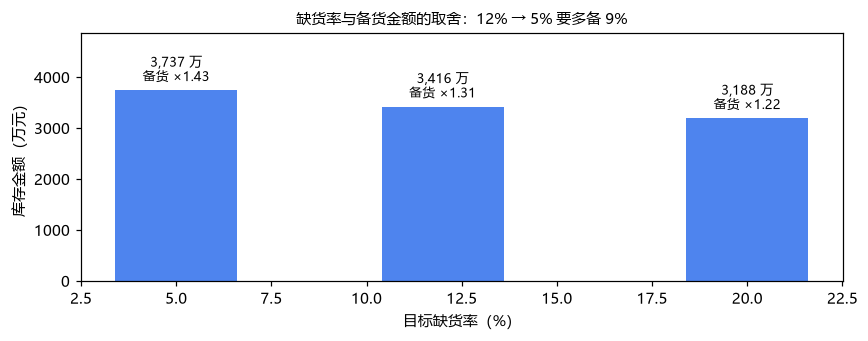

In [9]:
fig, ax1 = plt.subplots(figsize=(8.0, 3.2))
ax1.bar(stock["缺货率"] * 100, stock["库存金额（万元）"], width=3.2, color="#2f6feb", alpha=.85)
for _, r in stock.iterrows():
    ax1.annotate(f"{r['库存金额（万元）']:,.0f} 万\n备货 ×{r['备货量指数']:.2f}",
                 xy=(r["缺货率"] * 100, r["库存金额（万元）"]), xytext=(0, 6),
                 textcoords="offset points", ha="center", fontsize=8.5)
ax1.set_xlabel("目标缺货率（%）"); ax1.set_ylabel("库存金额（万元）")
ax1.set_ylim(0, stock["库存金额（万元）"].max() * 1.3)
ax1.set_title("缺货率与备货金额的取舍：12% → 5% 要多备 9%", fontsize=10)
plt.tight_layout(); plt.show()

从 12% 缺货率做到 5%，库存金额要多压 **9.4%**（3,416 万 → 3,737 万），换来的缺货率改善是 7 个百分点。

这个取舍必须由业务定：缺货损失的是 GMV 和体验，压货损失的是现金和折损率。
分析师的责任是把曲线算准，而不是替业务选点。

> 简历里的「缺货率 12% → 5%」就是这条曲线上的两个点。

## 5. 结论与局限

| 结论 | 数值 |
|---|---|
| GMV 同比 | +60.4% |
| 三层贡献 | 客流 28.7% / 转化 25.8% / 客单 45.5% |
| 分解闭合误差 | 0.00 元（恒等式，应恒为 0） |
| 客单价增长中的结构贡献 | 36%（15.3 / 42.8 元） |
| 增量集中度 | 数码 + 美妆 = 60% |
| 缺货率 12% → 5% 的代价 | 库存 +9.4% |

**局限（主动说）**：

1. **数据是同构的**：四个效应按已知参数埋入，所以闭合误差恰好为 0；
   真实项目里误差来自退款剔除、跨端 UV 去重、定金/尾款归属，通常在 2%~5%。
2. **没有做价格与促销的因果识别**：这里拆的是「会计恒等式」，不是「如果没做大促会怎样」。
   后者需要地理对照或合成控制，是另一个项目。
3. **备货模型是正态近似**：真实需求有厚尾和断档，建议用历史分位数或模拟法替代。
4. **没有算缺货的实际损失**：缺货率 → GMV 损失需要「缺货期间的替代购买率」，本项目没数据。

In [10]:
metrics = {
    "gmv_base": d["gmv_base"], "gmv_cur": d["gmv_cur"], "growth": d["growth"],
    "uv_contrib": d["uv_contrib"], "cvr_contrib": d["cvr_contrib"], "aov_contrib": d["aov_contrib"],
    "closure_error_pct": d["closure_error_pct"],
    "aov_mix_share": float(mix.loc[mix["指标"] == "客单价 AOV", "mix 占比"].iloc[0]),
    "top2_contrib": float(cc["contrib"].head(2).sum()),
    "stockout_12_to_5_inventory_uplift": float(
        stock.loc[stock["目标服务水平"] == 0.95, "库存金额（万元）"].iloc[0]
        / stock.loc[stock["目标服务水平"] == 0.88, "库存金额（万元）"].iloc[0] - 1),
}
(ROOT / "outputs" / "metrics.json").write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
metrics

{'gmv_base': 299260123.32,
 'gmv_cur': 480110333.68,
 'growth': 0.6043244531000083,
 'uv_contrib': 0.2872929811218912,
 'cvr_contrib': 0.2575067880100549,
 'aov_contrib': 0.45520023086805456,
 'closure_error_pct': -6.591603588045793e-16,
 'aov_mix_share': 0.3583931006734672,
 'top2_contrib': 0.5989112353499173,
 'stockout_12_to_5_inventory_uplift': 0.09397739850440501}